In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import classification_report, accuracy_score

In [2]:
df = pd.read_csv("medical_insurance.csv")
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1338 non-null   int64  
 1   gender                1338 non-null   object 
 2   bmi                   1338 non-null   float64
 3   children              1338 non-null   int64  
 4   discount_eligibility  1338 non-null   object 
 5   region                1338 non-null   object 
 6   expenses              1338 non-null   float64
 7   premium               1338 non-null   float64
dtypes: float64(3), int64(2), object(3)
memory usage: 83.8+ KB


(1338, 8)

In [3]:
print(f"find null value: \n {df.isnull().sum()}")
print(f"find dyplicate value: \n {df.duplicated().sum()}")

find null value: 
 age                     0
gender                  0
bmi                     0
children                0
discount_eligibility    0
region                  0
expenses                0
premium                 0
dtype: int64
find dyplicate value: 
 1


In [4]:
df = df.drop_duplicates().copy()

print(df.describe())

               age          bmi     children      expenses      premium
count  1337.000000  1337.000000  1337.000000   1337.000000  1337.000000
mean     39.222139    30.665520     1.095737  13279.121638   263.059038
std      14.044333     6.100664     1.205571  12110.359657   292.563876
min      18.000000    16.000000     0.000000   1121.870000    11.218700
25%      27.000000    26.300000     0.000000   4746.340000    87.994600
50%      39.000000    30.400000     1.000000   9386.160000   175.305000
75%      51.000000    34.700000     2.000000  16657.720000   343.031700
max      64.000000    53.100000     5.000000  63770.430000  1983.106400


In [5]:
df.dtypes

age                       int64
gender                   object
bmi                     float64
children                  int64
discount_eligibility     object
region                   object
expenses                float64
premium                 float64
dtype: object

In [6]:
for col in df.columns:
    print(df[col].unique())

[19 18 28 33 32 31 46 37 60 25 62 23 56 27 52 30 34 59 63 55 22 26 35 24
 41 38 36 21 48 40 58 53 43 64 20 61 44 57 29 45 54 49 47 51 42 50 39]
['female' 'male']
[27.9 33.8 33.  22.7 28.9 25.7 33.4 27.7 29.8 25.8 26.2 26.3 34.4 39.8
 42.1 24.6 30.8 23.8 40.3 35.3 36.  32.4 34.1 31.9 28.  23.1 32.8 17.4
 36.3 35.6 28.6 28.3 36.4 20.4 20.8 36.7 39.9 26.6 36.6 21.8 37.1 37.3
 38.7 34.8 24.5 35.2 33.6 28.7 37.  31.8 31.7 22.9 27.4 33.7 24.7 25.9
 22.4 39.1 36.2 24.  24.8 28.5 28.1 32.  34.  29.6 35.5 26.9 38.3 37.6
 41.2 31.2 27.2 27.  39.5 31.3 20.  19.3 31.6 25.5 30.1 29.9 27.5 28.4
 30.9 35.1 29.7 35.7 32.2 49.1 23.4 29.  31.4 33.9 28.8 37.4 17.8 34.7
 26.5 22.  35.9 25.6 25.2 32.5 25.3 38.8 30.5 37.7 24.1 24.4 27.8 36.9
 39.6 28.2 33.2 18.9 41.5 30.3 16.  33.3 29.2 26.4 30.7 41.9 32.1 30.6
 18.1 39.3 36.1 22.3 26.7 23.2 38.1 22.2 38.4 29.1 22.1 26.8 30.  20.9
 17.3 34.2 25.4 40.2 24.3 42.4 19.8 30.2 29.4 27.6 20.6 21.6 40.6 48.1
 36.8 45.5 23.  22.6 37.5 38.  34.9 33.1 40.9 36.5 34.5 3

In [7]:
df["premium_rate"] = (
    df["premium"] / df["expenses"]
)

print(
    df[
        [
            "expenses",
            "premium",
            "premium_rate",
            "discount_eligibility"
        ]
    ].head(10)
)

   expenses   premium  premium_rate discount_eligibility
0  16884.92  168.8492          0.01                  yes
1   1725.55   17.2555          0.01                   no
2   4449.46   44.4946          0.01                   no
3  21984.47  439.6894          0.02                   no
4   3866.86   77.3372          0.02                   no
5   3756.62   75.1324          0.02                   no
6   8240.59  164.8118          0.02                   no
7   7281.51  145.6302          0.02                   no
8   6406.41  128.1282          0.02                   no
9  28923.14  578.4628          0.02                   no


In [8]:
print(df["gender"].value_counts())
print(df["discount_eligibility"].value_counts())
print(df["region"].value_counts())

gender
male      675
female    662
Name: count, dtype: int64
discount_eligibility
no     1063
yes     274
Name: count, dtype: int64
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


In [9]:
print(
    df.groupby("discount_eligibility")[
        "premium_rate"
    ].agg(
        ["count", "mean", "min", "max", "std"]
    )
)

                      count      mean   min   max       std
discount_eligibility                                       
no                     1063  0.018024  0.01  0.04  0.007406
yes                     274  0.018139  0.01  0.04  0.007972


In [10]:
print(
    df.groupby("discount_eligibility")[
        "premium_rate"
    ].value_counts().head(20)
)

discount_eligibility  premium_rate
no                    0.02            515
                      0.01            266
                      0.02             98
                      0.01             51
                      0.04             50
                      0.02             33
                      0.01             31
                      0.04             16
                      0.04              3
yes                   0.02            123
                      0.01             65
                      0.02             29
                      0.01             23
                      0.04             17
                      0.01              7
                      0.02              5
                      0.04              3
                      0.04              2
Name: count, dtype: int64


In [11]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=[
        "0-20",
        "21-30",
        "31-40",
        "41-50",
        "51-60",
        "60+"
    ],
    include_lowest=True
)

print(
    df.groupby("age_group", observed=True)[
        "expenses"
    ].agg(["mean", "median", "count"])
)

                   mean     median  count
age_group                                
0-20        8756.355030   2203.470    165
21-30       9806.025432   3891.715    278
31-40      11639.308716   6334.340    257
41-50      14782.043132   8964.060    281
51-60      17062.293019  11938.260    265
60+        21063.163407  14394.560     91


In [12]:
print(
    df.groupby(
        pd.cut(df["bmi"], bins=5),
        observed=True
    )["expenses"].agg(
        ["mean", "median", "count"]
    )
)

                         mean     median  count
bmi                                            
(15.963, 23.42]   9414.657862   7985.820    159
(23.42, 30.84]   11605.997364   8931.505    550
(30.84, 38.26]   15790.802505  10118.420    483
(38.26, 45.68]   15258.427266  10387.880    128
(45.68, 53.1]    17289.422353   9549.570     17


In [13]:
print(
    df.groupby("region")["expenses"].agg(
        ["mean", "median", "count"]
    ).sort_values("mean", ascending=False)
)

                   mean     median  count
region                                   
southeast  14735.411538   9294.130    364
northeast  13406.384691  10057.655    324
northwest  12450.840648   8976.980    324
southwest  12346.937908   8798.590    325


In [14]:
X = df[
    [
        "age",
        "gender",
        "bmi",
        "children",
        "discount_eligibility",
        "region"
    ]
]

y = df["expenses"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1337, 6)
Target shape: (1337,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42 )

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1069, 6)
Testing data: (268, 6)


In [16]:
numeric_features = [
    "age",
    "bmi",
    "children"
]

categorical_features = [
    "gender",
    "discount_eligibility",
    "region"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [17]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [18]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.head())

print("\nPredicted values:")
print(y_pred[:5])

Actual values:
900      8688.86
1064     5708.87
1256    11436.74
298     38746.36
237      4463.21
Name: expenses, dtype: float64

Predicted values:
[ 8135.94784906  5737.53051009 14375.4878467  31749.21910772
  8966.53643436]


In [19]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 4))

MAE: 4177.27
RMSE: 5956.63
R²: 0.8069


In [20]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                max_depth=None
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [21]:
print("MAE:",
      mean_absolute_error(y_test, rf_pred))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, rf_pred)))

print("R2:",
      r2_score(y_test, rf_pred))

MAE: 2564.5389083333334
RMSE: 4629.792086787132
R2: 0.8833509285338724


In [22]:
from xgboost import XGBRegressor

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBRegressor(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=4,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42
            )
        )
    ]
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

In [23]:
xgb_mae = mean_absolute_error(y_test, xgb_pred)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_pred)
)

xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)
print("XGBoost R2:", xgb_r2)

XGBoost MAE: 2668.3712507287783
XGBoost RMSE: 4466.787298838539
XGBoost R2: 0.8914202456775702


In [24]:
results = {
    "Linear Regression": [
        mean_absolute_error(y_test, y_pred),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        r2_score(y_test, y_pred)
    ],

    "Random Forest": [
        mean_absolute_error(y_test, rf_pred),
        np.sqrt(mean_squared_error(y_test, rf_pred)),
        r2_score(y_test, rf_pred)
    ],

    "XGBoost": [
        xgb_mae,
        xgb_rmse,
        xgb_r2
    ]
}

In [25]:
results_df = pd.DataFrame(
    results,
    index=["MAE", "RMSE", "R2"]
).T

print(results_df)

                           MAE         RMSE        R2
Linear Regression  4177.267596  5956.632572  0.806910
Random Forest      2564.538908  4629.792087  0.883351
XGBoost            2668.371251  4466.787299  0.891420


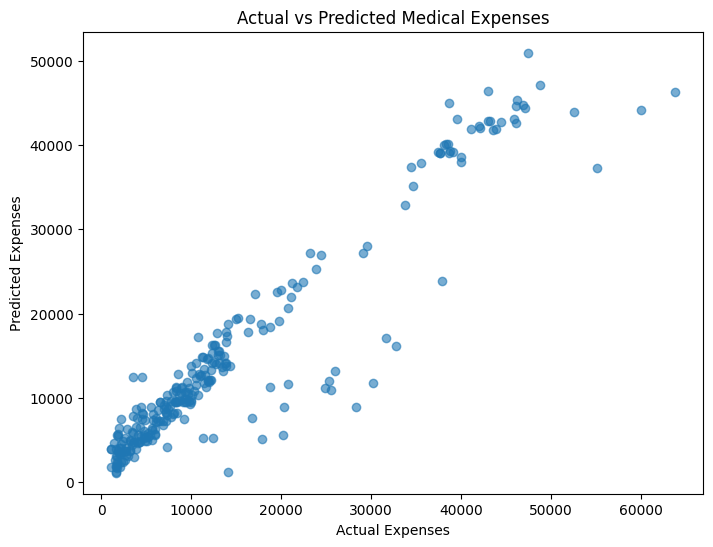

In [28]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    xgb_pred,
    alpha=0.6
)

plt.xlabel("Actual Expenses")
plt.ylabel("Predicted Expenses")
plt.title("Actual vs Predicted Medical Expenses")

plt.show()

In [27]:
import joblib

joblib.dump(
    xgb_model,
    "medical_expense_model.pkl"
)

['medical_expense_model.pkl']